# **Carga y descripción del dataset**

In [1]:
#Section to import all the libraries

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

#Adding library to get norm curve for the data
from scipy.stats import norm
#Adding library to display dataframe data
from IPython.display import display

from pathlib import Path
import sys

project_root = Path.cwd().parent  # from Proyecto\notebooks, this is Proyecto
sys.path.insert(0, str(project_root))

from mibici.config import CONFIG

2026-10-18 03:04:10.034 | INFO     | mibici.config:<module>:12 - PROJ_ROOT path is: E:\GitHub\TC5061-Proyecto-Equipo29


In [2]:
#Loading the data from the CSV file, taking file name and path from the config.py file
def load_data_from_config_file():
    file_path = CONFIG.processed_data_dir / CONFIG.output_filename
    dataframe = pd.read_parquet(file_path)

    return dataframe

df = load_data_from_config_file()

# Use method shape to get rows and column numbers
print(f"Tamaño del DataFrame:", df.shape)
print(f"\n")

# Use method info from pandas to get summary types
print(f"Utilizando método info() para obtener un resumen de los tipos:")
display(df.info())

# Print first 5 rows to verify data
print(f"Utilizando método head() para obtener los primeros 5 registros del dataframe:")
display(df.head(5))

# Get Nan percentage values for every column
print(f"\nTotal de valores faltantes")
print(df.isna().mean() * 100)

# Get Nan percentage values for every column
print(f"\nTotal de valores duplicados")
print(df.duplicated().sum())
print(f"\n")

# Get numerical and categorical columns number which will be useful for graphics
num_cols = df.select_dtypes(include='number').columns.tolist()
cat_cols  = df.select_dtypes(include=['str', 'category']).columns.tolist()

print(f"Columnas númericas: ", num_cols)
print(f"Columnas categoricas: ", cat_cols)

Tamaño del DataFrame: (7894097, 16)


Utilizando método info() para obtener un resumen de los tipos:
<class 'pandas.DataFrame'>
RangeIndex: 7894097 entries, 0 to 7894096
Data columns (total 16 columns):
 #   Column               Dtype         
---  ------               -----         
 0   Viaje_Id             int64         
 1   Usuario_Id           int64         
 2   Genero               str           
 3   Año_de_nacimiento    float64       
 4   Inicio_del_viaje     datetime64[us]
 5   Fin_del_viaje        datetime64[us]
 6   Origen_Id            Int64         
 7   Destino_Id           Int64         
 8   origen_nombre        str           
 9   origen_latitud       float64       
 10  origen_longitud      float64       
 11  origen_dpcapacidad   float64       
 12  destino_nombre       str           
 13  destino_latitud      float64       
 14  destino_longitud     float64       
 15  destino_dpcapacidad  float64       
dtypes: Int64(2), datetime64[us](2), float64(7), int64(2), 

None

Utilizando método head() para obtener los primeros 5 registros del dataframe:


,Viaje_Id,Usuario_Id,Genero,Año_de_nacimiento,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id,origen_nombre,origen_latitud,origen_longitud,origen_dpcapacidad,destino_nombre,destino_latitud,destino_longitud,destino_dpcapacidad
0,37162342,601273,M,1982.0,2025-01-01 00:00:44,2025-01-01 00:11:29,211,395,(GDL-144) C. Primo Feliciano / C. San Gabriel,20.669931,-103.394307,11.0,(GDL-276) Francisco de Quevedo / Miguel Lerdo,20.671045,-103.381349,19.0
1,37162343,1571524,M,2003.0,2025-01-01 00:04:11,2025-01-01 00:15:07,35,260,(GDL-033) Av. Hidalgo / C. Pedro Loza,20.677419,-103.347983,15.0,(GDL-187) Av. 16 de Septiembre / C. Priscilia,20.672639,-103.347155,15.0
2,37162344,1435200,F,1984.0,2025-01-01 00:05:27,2025-01-01 00:15:23,35,260,(GDL-033) Av. Hidalgo / C. Pedro Loza,20.677419,-103.347983,15.0,(GDL-187) Av. 16 de Septiembre / C. Priscilia,20.672639,-103.347155,15.0
3,37162345,126327,M,1988.0,2025-01-01 00:07:47,2025-01-01 00:17:42,190,11,(GDL-123) C. Aurelio L. Gallardo / Av. México,20.679450,-103.376000,11.0,(GDL-009) Calz. Federalismo/ C. J. Angulo,20.682077,-103.353835,23.0
4,37162346,416121,M,1994.0,2025-01-01 00:08:52,2025-01-01 00:18:10,273,8,(GDL-200) Av. Alcalde /Av. Manuel A. Camacho,20.694060,-103.348240,23.0,(GDL-006) C. Venustiano Carranza /C. Reforma,20.680717,-103.344415,11.0



Total de valores faltantes
Viaje_Id               0.000000
Usuario_Id             0.000000
Genero                 0.794809
Año_de_nacimiento      0.018191
Inicio_del_viaje       0.000000
Fin_del_viaje          0.000000
Origen_Id              0.000000
Destino_Id             0.000000
origen_nombre          0.024829
origen_latitud         0.024829
origen_longitud        0.024829
origen_dpcapacidad     0.024829
destino_nombre         0.026894
destino_latitud        0.026894
destino_longitud       0.026894
destino_dpcapacidad    0.026894
dtype: float64

Total de valores duplicados
758


Columnas númericas:  ['Viaje_Id', 'Usuario_Id', 'Año_de_nacimiento', 'Origen_Id', 'Destino_Id', 'origen_latitud', 'origen_longitud', 'origen_dpcapacidad', 'destino_latitud', 'destino_longitud', 'destino_dpcapacidad']
Columnas categoricas:  ['Genero', 'origen_nombre', 'destino_nombre']


# **EDA**

In [3]:
def dataframe_getStatisticalDescription(df, isNumerical=True, plotRows=4, plotCols=3, plotLimit=1):
  # Numerical values
  cols = list()
  if isNumerical:
    cols = df.select_dtypes(include='number').columns.to_list()

    # ** Numerical values **
    print(f'**************************************************')
    print(f'** Datos numericos -- Estadisticas descriptivas **')
    print(f'**************************************************')

    # Get descriptive statistics from the dataframe adding skewness and kurtosis
    desc = df[num_cols].describe()

    # Get Skewness (Asymmetry) and Kurtosis
    skewness = df.skew(numeric_only=True).to_frame(name='skew').T
    kurtosis = df.kurt(numeric_only=True).to_frame(name='kurtosis').T

    # Combine in single datagrame using concat method
    desc = pd.concat([desc, skewness, kurtosis])

    print(f'** Estadisticas descriptivas del dataframe para sus valores numéricos **\n')
    display(desc.T)

    print(f'\n')

    # ** Generating histograms using matplotlib and seaborn **
    fig, axes = plt.subplots(plotRows, plotCols, figsize=(16, 12)) # ---> Matplotlib
    plt.subplots_adjust(wspace=0.5)

    axes = axes.ravel()

    for col, ax in zip(num_cols, axes):
      values = df[col].dropna() # Check if this is just 1 value to graphic curve
      
      # Histograma
      n, bins, patches = ax.hist(values, density=True)
      
      if values.nunique() > 1:
        # KDE
        sns.kdeplot(df[col], ax=ax, color='red', warn_singular=False)

        # Parámetros de distribución normal
        mu = df[col].mean()
        sigma = df[col].std()

        # Valores para curva normal
        x_vals = np.linspace(df[col].min(), df[col].max(), 1000)

        normal_ref = norm.pdf(x_vals, loc=mu, scale=sigma)
        # Graficar curva normal
        ax.plot(x_vals, normal_ref, linestyle='--', label='Normal')

        ax.set_xticks(bins) #Draw bins
        ax.set(title=f'{col}', xlabel=None)
        ax.set_xlabel(None)
        # Rotar etiquetas del eje x
        ax.tick_params(axis='x', rotation=90)

    for plotNo in range(len(cols), len(axes)):
      if plotNo >= plotLimit: fig.delaxes(axes[plotNo])  # Removes the empty subplot entirely

    plt.tight_layout()
    plt.show()
    print(f'\n')

  # Categorical values
  else:
    cols  = df.select_dtypes(include=['object', 'str']).columns.tolist()
    
    # ** Categorical values **
    print(f'***************************************************')
    print(f'** Datos categoricos - Estadisticas descriptivas **')
    print(f'***************************************************\n')

    # ** Categorical values **
    print(f'** Estadisticas descriptivas del dataframe para sus valores categoricos **\n')
    display(df[cat_cols].describe().T)

    print(f'\nFrecuencia de las categorias.')
    for col in cat_cols:
      display(df[col].value_counts())

    print(f'\n')

    fig, axes = plt.subplots(plotRows, plotCols, figsize=(18,5))
    plt.subplots_adjust(hspace=0.5)
    axes = axes.ravel()
    for col, ax in zip(cat_cols, axes):
      # Get cardinality
      cardinality = df[col].nunique()
      #Check if cardinality is highter than 10 to check for frequent values
      if cardinality > 10:
        # Top 10 more frequent values
        top_10 = df[col].value_counts().nlargest(10).index

        # Filter dataframe to verify if data is in top 10
        filtered_df = df[df[col].isin(top_10)]

        #Assign these values to the plot
        xPlot = filtered_df[col]
        huePlot = filtered_df[col]
      else:
        # Not high cardinality, take values normally
        xPlot = df[col]
        huePlot = df[col]
        pass

      sns.countplot(x=xPlot, hue=huePlot, ax=ax) # ---> Seaborn

      ax.set(title=f'{col}', xlabel=None)
      ax.tick_params(axis='x',rotation=90)
      
    for plotNo in range(len(cols), len(axes)):
      if plotNo >= plotLimit: fig.delaxes(axes[plotNo])  # Removes the empty subplot entirely

    plt.tight_layout()
    plt.show()
    print(f'\n')

**************************************************
** Datos numericos -- Estadisticas descriptivas **
**************************************************
** Estadisticas descriptivas del dataframe para sus valores numéricos **



,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
Viaje_Id,7894097.0,41698615.155573,2627989.659967,37162342.0,39420223.0,41686211.0,43948440.0,46255558.0,0.013928,-1.195408
Usuario_Id,7894097.0,2582881.776591,1766340.913486,102.0,652600.0,2554316.0,4516124.0,5006315.0,-0.090646,-1.646073
Año_de_nacimiento,7892661.0,1990.48101,15.869021,199.0,1985.0,1993.0,1999.0,2023.0,-57.95916,6501.469457
Origen_Id,7894097.0,159.977298,117.883425,2.0,51.0,157.0,260.0,519.0,0.460312,-0.92531
Destino_Id,7894097.0,161.805317,120.557657,2.0,51.0,157.0,266.0,519.0,0.444101,-1.020371
origen_latitud,7892137.0,20.679495,0.016551,20.63613,20.670512,20.676067,20.68504,20.739523,1.177052,2.553213
origen_longitud,7892137.0,-103.360546,0.019402,-103.433215,-103.372444,-103.358466,-103.348078,-103.297112,-0.197497,0.781764
origen_dpcapacidad,7892137.0,18.254287,5.426107,11.0,15.0,19.0,19.0,39.0,1.499154,3.133747
destino_latitud,7891974.0,20.679944,0.016451,20.63613,20.670923,20.676337,20.68586,20.739523,1.120257,2.348664
destino_longitud,7891974.0,-103.358759,0.018565,-103.433215,-103.369349,-103.355592,-103.34796,-103.297112,-0.27984,0.920599


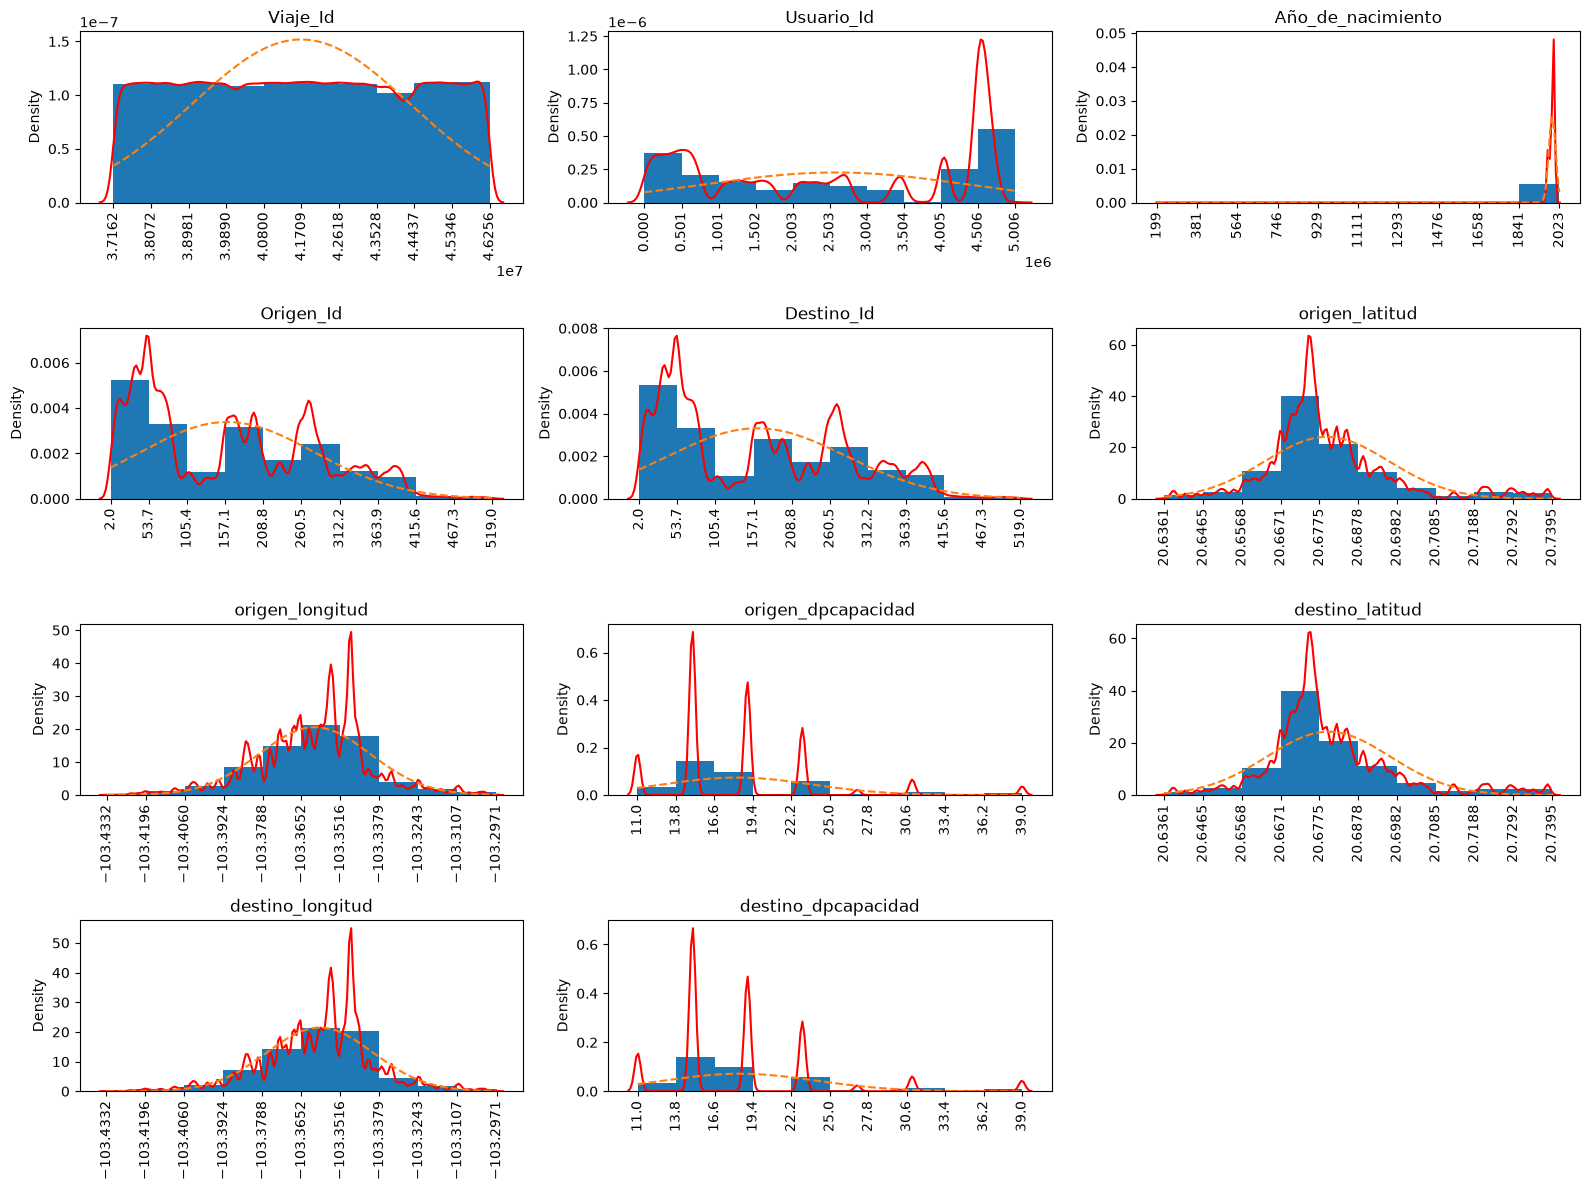




Generamos un boxplot de las variables numericas para revisar outliers...


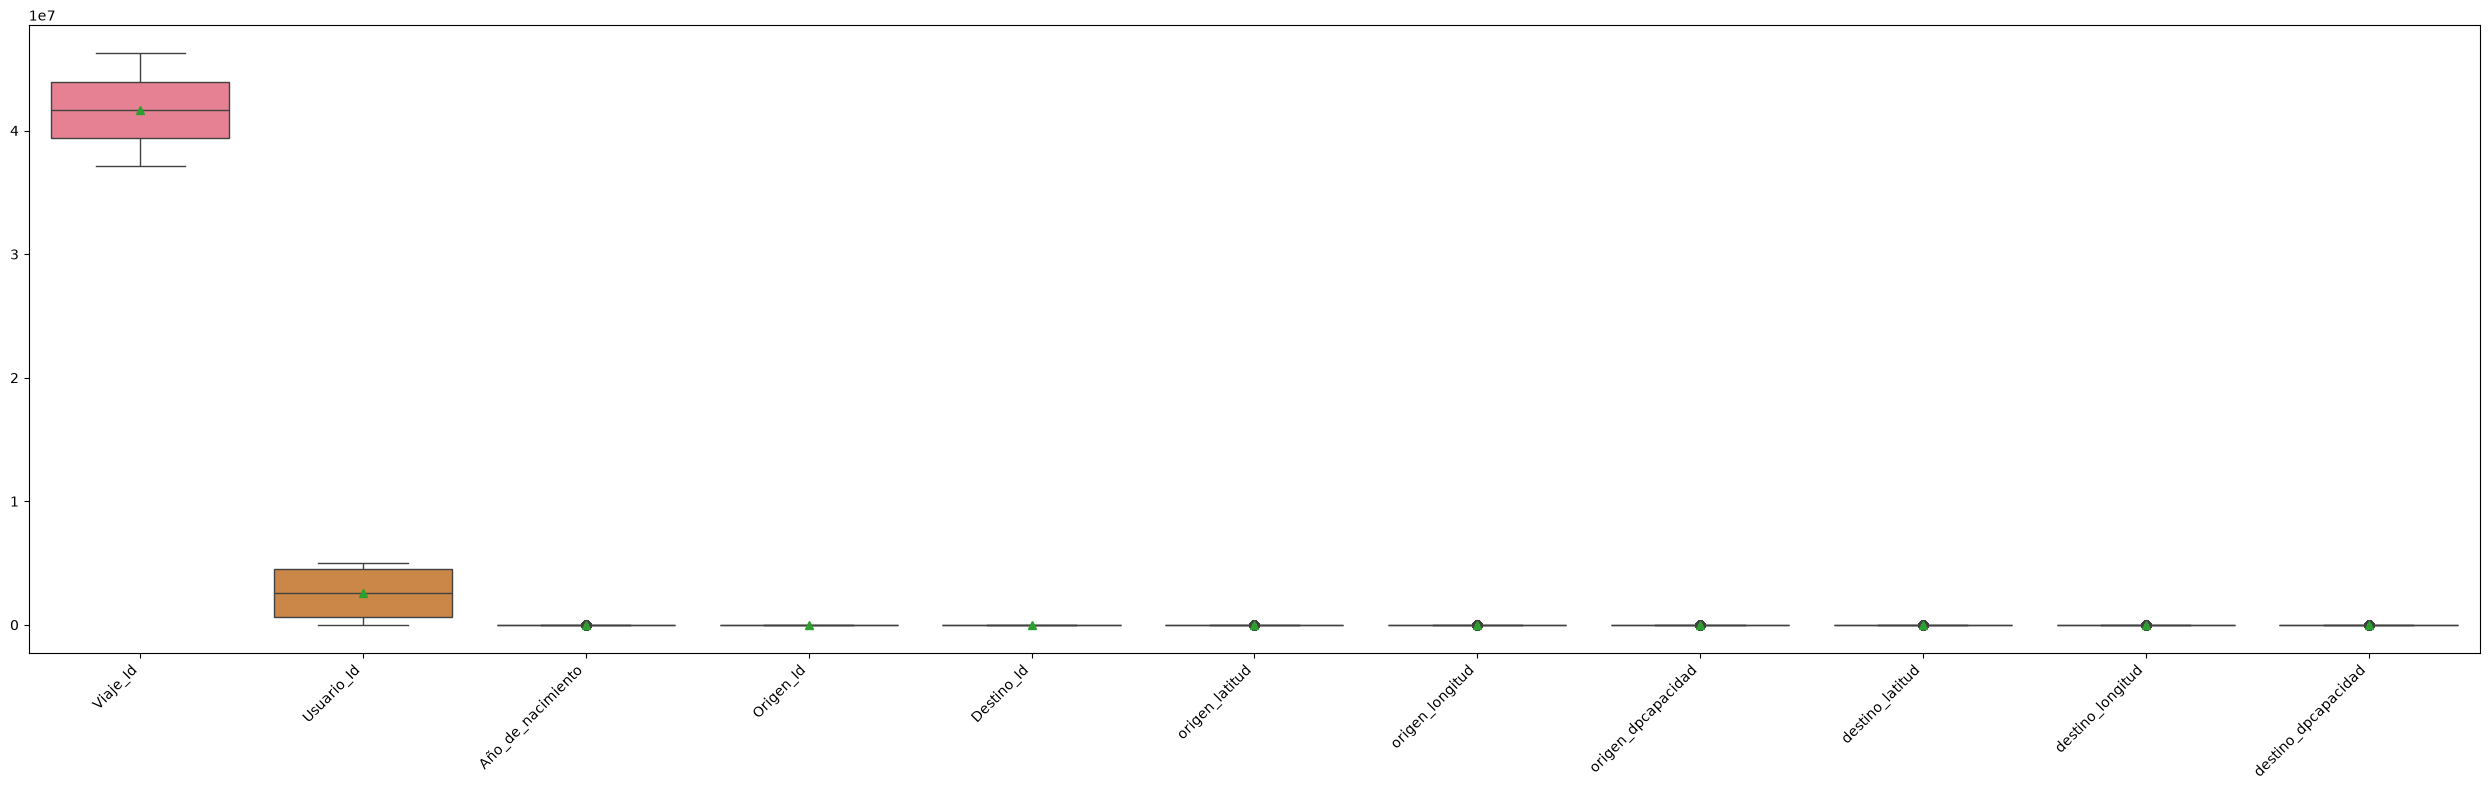

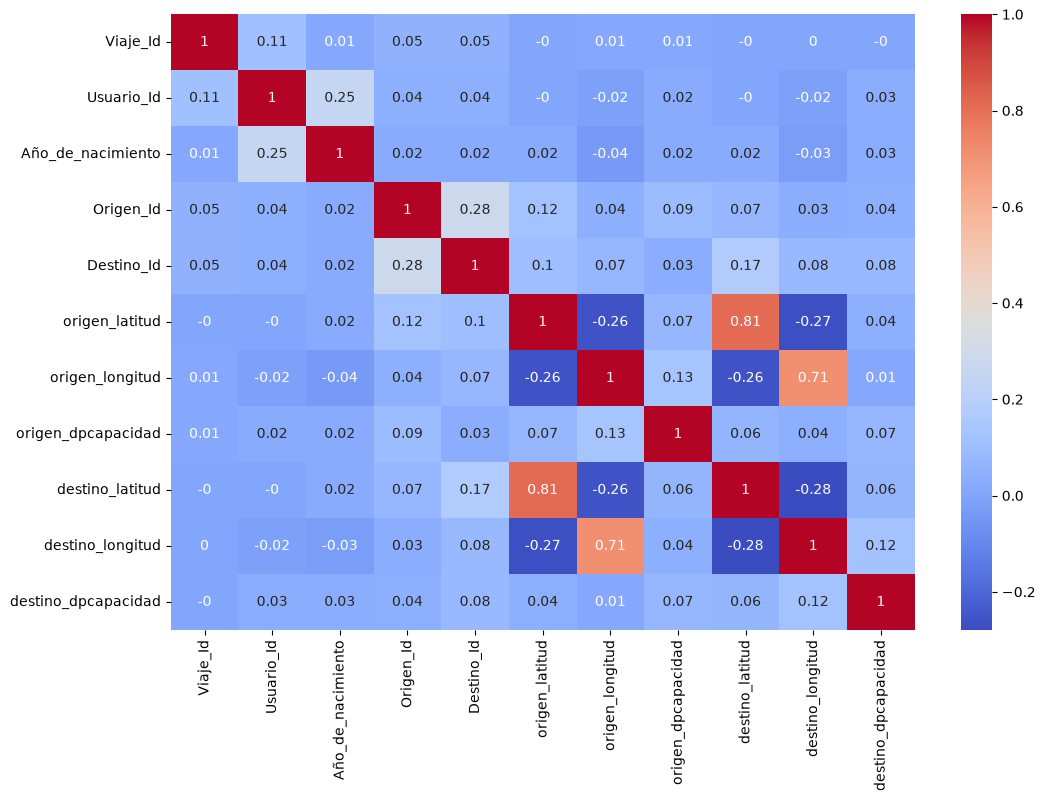

In [4]:
dataframe_getStatisticalDescription(df, True, 4, 3, len(num_cols))

# Create boxplots for numerical values to check their values and outliers
print("\nGeneramos un boxplot de las variables numericas para revisar outliers...")
plt.figure(figsize=(25,8))
sns.boxplot(data=df[num_cols],
            showmeans=True)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Get correlation matrix
corr_matrix = df[num_cols].corr()

print("\n")
plt.figure(figsize = (12, 8))
sns.heatmap(round(corr_matrix,2), annot=True, cmap='coolwarm')
plt.show()

***************************************************
** Datos categoricos - Estadisticas descriptivas **
***************************************************

** Estadisticas descriptivas del dataframe para sus valores categoricos **



,count,unique,top,freq
Genero,7831354,2,M,5674158
origen_nombre,7892137,470,(GDL-049) Lopez Cotilla / Penitenciaría,161975
destino_nombre,7891974,470,(GDL-049) Lopez Cotilla / Penitenciaría,198244



Frecuencia de las categorias.


Genero
M    5674158
F    2157196
Name: count, dtype: int64

origen_nombre
(GDL-049) Lopez Cotilla / Penitenciaría        161975
(GDL-033) Av. Hidalgo / C. Pedro Loza          129786
(GDL-198) Av. Alcalde / C. Hospital            120327
(GDL-009) Calz. Federalismo/ C. J. Angulo      115317
(GDL-050) C.Pedro Moreno /Federalismo           99306
                                                ...  
(ZPN-102) C. Volcán del Colli/V. del Ajusco       191
(ZPN-100)  C. Popocatépetl / C. Volcán Barú       180
(ZPN-101) C. Volcán Quinceo/C. Ignacio C.         159
(GDL-335) Dionisio Rdgz/González Bocanegra        142
(ZPN-094) Av. V. el Colli / C. V. Paricutín       120
Name: count, Length: 470, dtype: int64

destino_nombre
(GDL-049) Lopez Cotilla / Penitenciaría          198244
(GDL-033) Av. Hidalgo / C. Pedro Loza            153227
(GDL-198) Av. Alcalde / C. Hospital              108541
(GDL-009) Calz. Federalismo/ C. J. Angulo        106887
(GDL-048) C. Constancio Hernández/ Av. Juaréz     99166
                                                  ...  
(ZPN-099) C. Playa Olas / Av. El Colli              174
(ZPN-089) C. Arquitectos/Av. San Luis Gonzaga       153
(ZPN-101) C. Volcán Quinceo/C. Ignacio C.           150
(GDL-335) Dionisio Rdgz/González Bocanegra          139
(ZPN-094) Av. V. el Colli / C. V. Paricutín          95
Name: count, Length: 470, dtype: int64

C:\Users\Ulises\AppData\Local\Temp\ipykernel_11604\2803015095.py:117: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout()


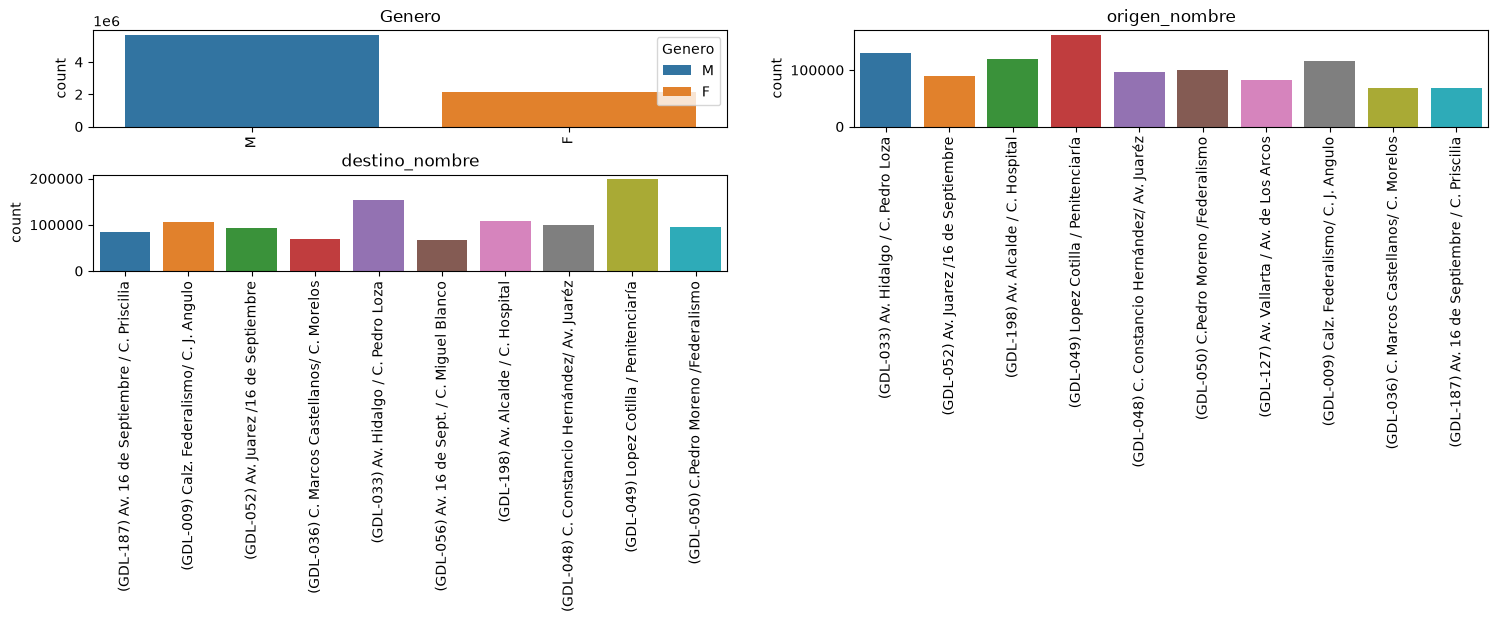

In [5]:
dataframe_getStatisticalDescription(df, False, 3, 2, len(cat_cols))

In [6]:
print("Mostramos 5 datos donde 'origen_nombre' es nulo")
display(df[df["origen_nombre"].isna()].head(5))

print("\nMostramos 5 datos donde 'destino_nombre' es nulo")
display(df[df["destino_nombre"].isna()].head(5))

print(f"\nNumero de columnas con fechas menor a 1900: ", (df["Año_de_nacimiento"] < 1900).sum())

Mostramos 5 datos donde 'origen_nombre' es nulo


,Viaje_Id,Usuario_Id,Genero,Año_de_nacimiento,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id,origen_nombre,origen_latitud,origen_longitud,origen_dpcapacidad,destino_nombre,destino_latitud,destino_longitud,destino_dpcapacidad
6351087,44506478,4661446,F,1996.0,2026-06-08 18:03:12,2026-06-08 18:04:00,405,405,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6351148,44506540,107662,F,1989.0,2026-06-08 18:05:56,2026-06-08 18:08:10,405,405,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6351170,44506562,4661446,F,1996.0,2026-06-08 18:06:44,2026-06-08 19:03:17,405,405,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6383440,44544031,1300200,M,1970.0,2026-06-11 10:44:09,2026-06-11 11:02:00,407,8,NaN,NaN,NaN,NaN,(GDL-006) C. Venustiano Carranza /C. Reforma,20.680717,-103.344415,11.0
6383654,44544284,4054031,M,2004.0,2026-06-11 11:07:53,2026-06-11 11:07:57,407,407,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Mostramos 5 datos donde 'destino_nombre' es nulo


,Viaje_Id,Usuario_Id,Genero,Año_de_nacimiento,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id,origen_nombre,origen_latitud,origen_longitud,origen_dpcapacidad,destino_nombre,destino_latitud,destino_longitud,destino_dpcapacidad
6351087,44506478,4661446,F,1996.0,2026-06-08 18:03:12,2026-06-08 18:04:00,405,405,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6351148,44506540,107662,F,1989.0,2026-06-08 18:05:56,2026-06-08 18:08:10,405,405,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6351170,44506562,4661446,F,1996.0,2026-06-08 18:06:44,2026-06-08 19:03:17,405,405,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6383128,44543675,4532223,F,1964.0,2026-06-11 10:11:40,2026-06-11 10:35:26,397,407,(GDL-279) Belen / Av. de los Maestros,20.693053,-103.3459,19.0,NaN,NaN,NaN,NaN
6383130,44543677,574555,M,1991.0,2026-06-11 10:11:48,2026-06-11 10:35:24,397,407,(GDL-279) Belen / Av. de los Maestros,20.693053,-103.3459,19.0,NaN,NaN,NaN,NaN



Numero de columnas con fechas menor a 1900:  319


# Limpieza de datos.

In [7]:
#Drop rows where Origen_Id is null and rows where Destino_Id is null, as it does not find id for the station
df = df.dropna(subset=["origen_nombre"])
df = df.dropna(subset=["destino_nombre"])

#Drop columns that does not have meaningful data for the model
df = df.drop(columns=['Viaje_Id', 'Usuario_Id', 'Origen_Id', 'Destino_Id', 'origen_nombre', 'destino_nombre'])

#Drop columns with incorrect data for year of birth
df = df.drop(df[df["Año_de_nacimiento"] < 1900].index)

# For gender, to preserve data, replace NaN values with "desconocido"
df["Genero"] = df["Genero"].fillna("Desconocido")

#For year of birth, impute with median
df["Año_de_nacimiento"] = df["Año_de_nacimiento"].fillna(df["Año_de_nacimiento"].median())

#Drop duplicates
df = df.drop_duplicates()


# Use method shape to get rows and column numbers
print(f"Tamaño del DataFrame:", df.shape)
print(f"\n")

# Use method info from pandas to get summary types
print(f"Utilizando método info() para obtener un resumen de los tipos:")
display(df.info())

# Print first 5 rows to verify data
print(f"Utilizando método head() para obtener los primeros 5 registros del dataframe:")
display(df.head(5))

# Get Nan percentage values for every column
print(f"\nTotal de valores faltantes")
print(df.isna().mean() * 100)

# Get Nan percentage values for every column
print(f"\nTotal de valores duplicados")
print(df.duplicated().sum())
print(f"\n")

# Get numerical and categorical columns number which will be useful for graphics
num_cols = df.select_dtypes(include='number').columns.tolist()
cat_cols  = df.select_dtypes(include=['str', 'category']).columns.tolist()

print(f"Columnas númericas: ", num_cols)
print(f"Columnas categoricas: ", cat_cols)

Tamaño del DataFrame: (7888939, 10)


Utilizando método info() para obtener un resumen de los tipos:
<class 'pandas.DataFrame'>
Index: 7888939 entries, 0 to 7894096
Data columns (total 10 columns):
 #   Column               Dtype         
---  ------               -----         
 0   Genero               str           
 1   Año_de_nacimiento    float64       
 2   Inicio_del_viaje     datetime64[us]
 3   Fin_del_viaje        datetime64[us]
 4   origen_latitud       float64       
 5   origen_longitud      float64       
 6   origen_dpcapacidad   float64       
 7   destino_latitud      float64       
 8   destino_longitud     float64       
 9   destino_dpcapacidad  float64       
dtypes: datetime64[us](2), float64(7), str(1)
memory usage: 671.1 MB


None

Utilizando método head() para obtener los primeros 5 registros del dataframe:


,Genero,Año_de_nacimiento,Inicio_del_viaje,Fin_del_viaje,origen_latitud,origen_longitud,origen_dpcapacidad,destino_latitud,destino_longitud,destino_dpcapacidad
0,M,1982.0,2025-01-01 00:00:44,2025-01-01 00:11:29,20.669931,-103.394307,11.0,20.671045,-103.381349,19.0
1,M,2003.0,2025-01-01 00:04:11,2025-01-01 00:15:07,20.677419,-103.347983,15.0,20.672639,-103.347155,15.0
2,F,1984.0,2025-01-01 00:05:27,2025-01-01 00:15:23,20.677419,-103.347983,15.0,20.672639,-103.347155,15.0
3,M,1988.0,2025-01-01 00:07:47,2025-01-01 00:17:42,20.679450,-103.376000,11.0,20.682077,-103.353835,23.0
4,M,1994.0,2025-01-01 00:08:52,2025-01-01 00:18:10,20.694060,-103.348240,23.0,20.680717,-103.344415,11.0



Total de valores faltantes
Genero                 0.0
Año_de_nacimiento      0.0
Inicio_del_viaje       0.0
Fin_del_viaje          0.0
origen_latitud         0.0
origen_longitud        0.0
origen_dpcapacidad     0.0
destino_latitud        0.0
destino_longitud       0.0
destino_dpcapacidad    0.0
dtype: float64

Total de valores duplicados
0


Columnas númericas:  ['Año_de_nacimiento', 'origen_latitud', 'origen_longitud', 'origen_dpcapacidad', 'destino_latitud', 'destino_longitud', 'destino_dpcapacidad']
Columnas categoricas:  ['Genero']


**************************************************
** Datos numericos -- Estadisticas descriptivas **
**************************************************
** Estadisticas descriptivas del dataframe para sus valores numéricos **



,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
Año_de_nacimiento,7888939.0,1990.553267,11.098853,1920.000000,1985.000000,1993.000000,1999.000000,2023.000000,-1.006947,0.604731
origen_latitud,7888939.0,20.679496,0.016550,20.636130,20.670512,20.676067,20.685040,20.739523,1.177761,2.553503
origen_longitud,7888939.0,-103.360550,0.019400,-103.433215,-103.372444,-103.358466,-103.348078,-103.297112,-0.197999,0.781164
origen_dpcapacidad,7888939.0,18.254192,5.426158,11.000000,15.000000,19.000000,19.000000,39.000000,1.499137,3.133742
destino_latitud,7888939.0,20.679944,0.016450,20.636130,20.670923,20.676337,20.685860,20.739523,1.121058,2.349065
destino_longitud,7888939.0,-103.358763,0.018564,-103.433215,-103.369349,-103.355592,-103.347960,-103.297112,-0.280202,0.920268
destino_dpcapacidad,7888939.0,18.452322,5.563074,11.000000,15.000000,19.000000,19.000000,39.000000,1.536175,3.167801


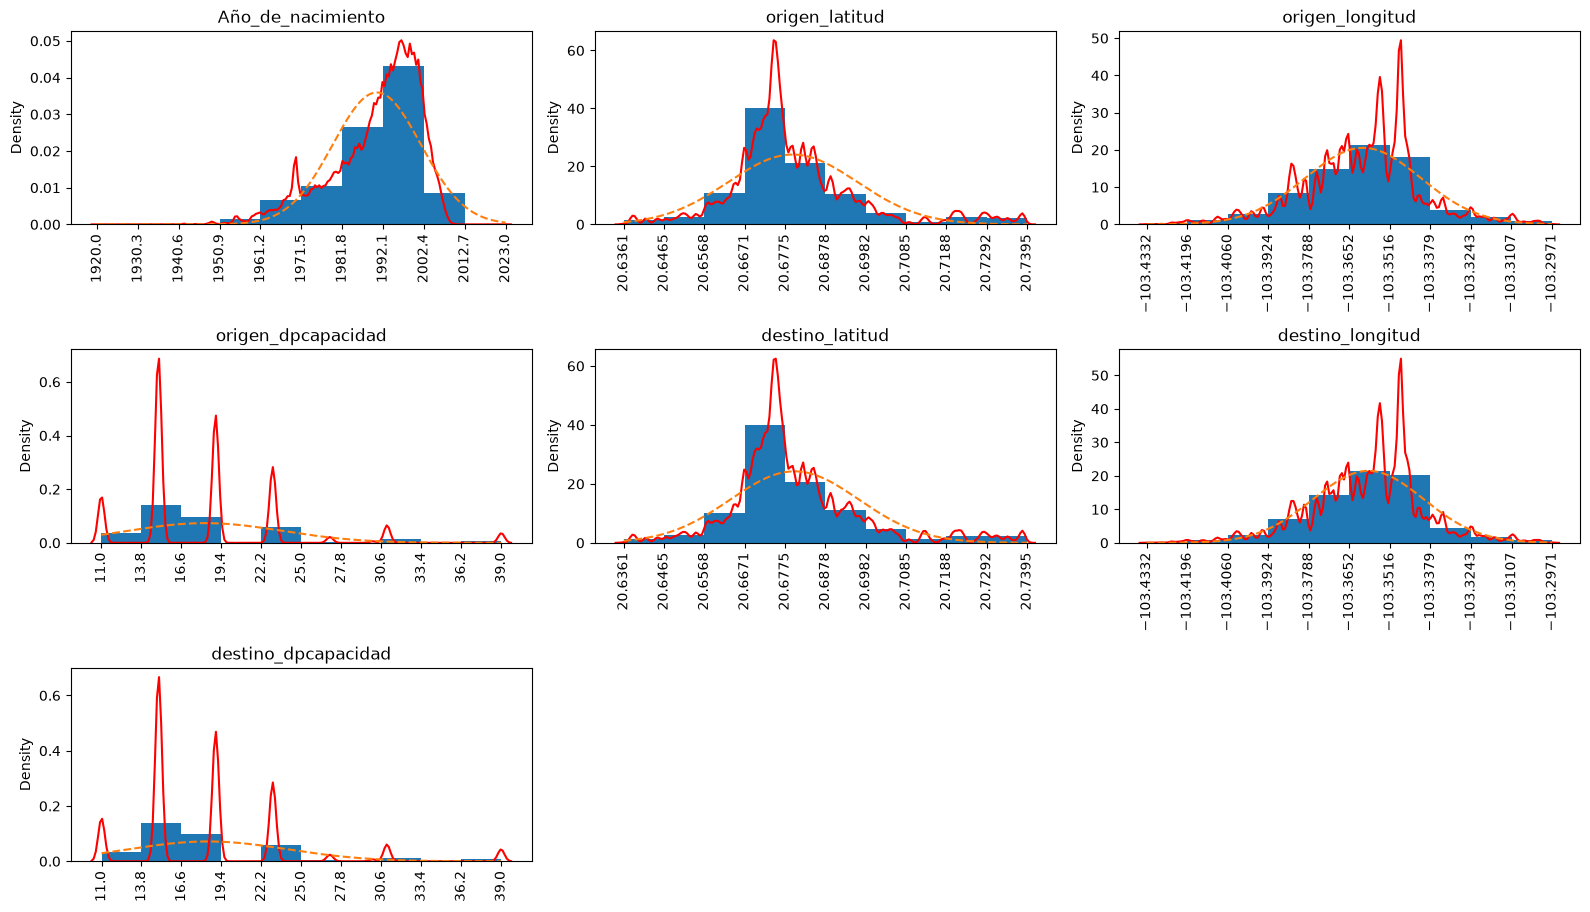




Generamos un boxplot de las variables numericas para revisar outliers...


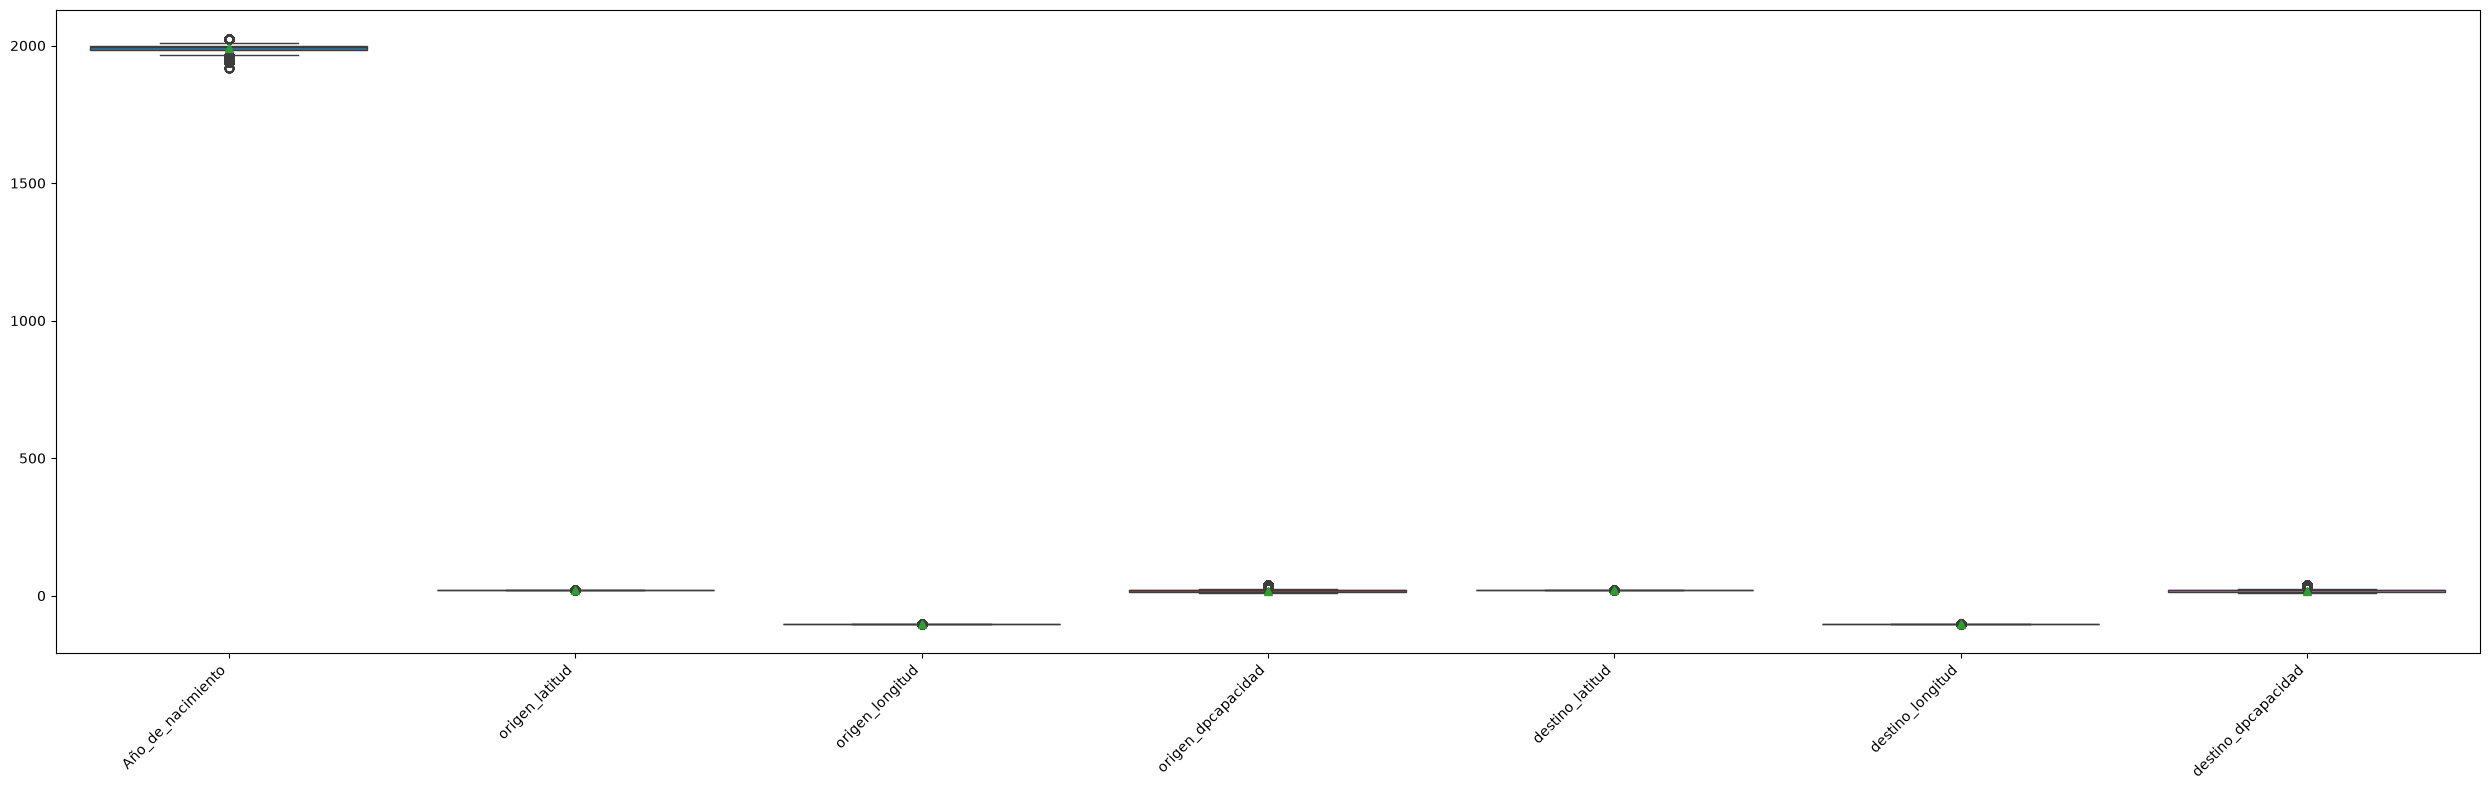

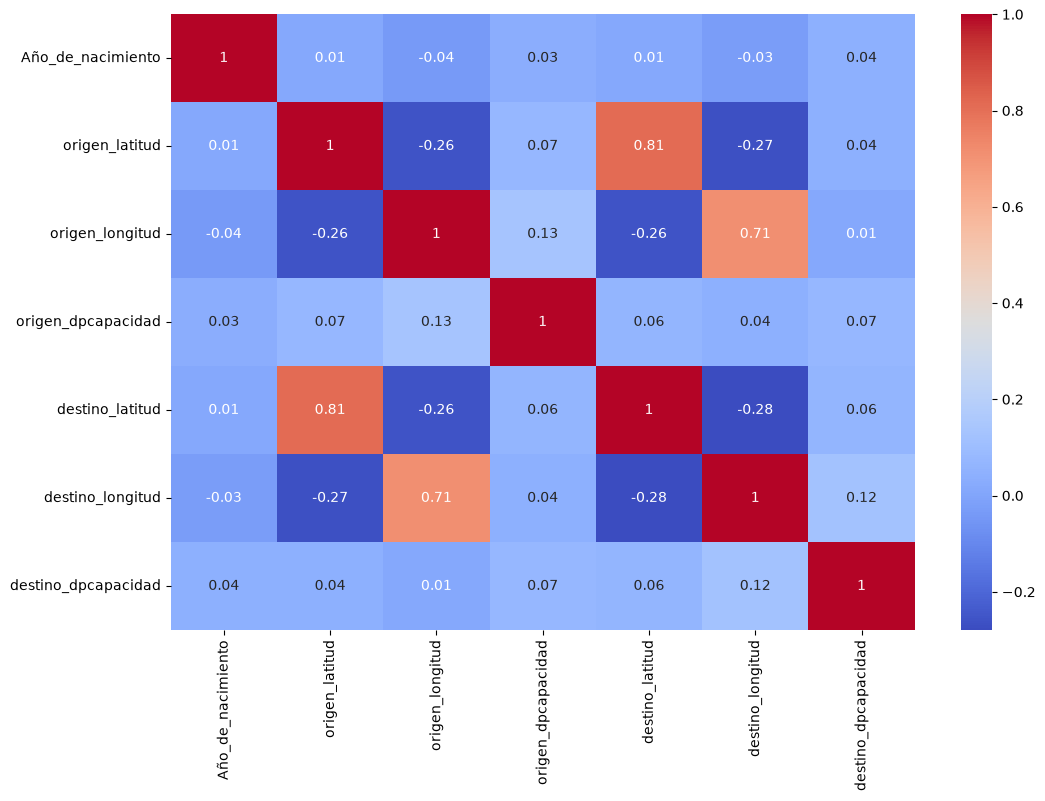

In [8]:
dataframe_getStatisticalDescription(df, True, 4, 3, len(num_cols))

# Create boxplots for numerical values to check their values and outliers
print("\nGeneramos un boxplot de las variables numericas para revisar outliers...")
plt.figure(figsize=(25,8))
sns.boxplot(data=df[num_cols],
            showmeans=True)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Get correlation matrix
corr_matrix = df[num_cols].corr()

print("\n")
plt.figure(figsize = (12, 8))
sns.heatmap(round(corr_matrix,2), annot=True, cmap='coolwarm')
plt.show()

***************************************************
** Datos categoricos - Estadisticas descriptivas **
***************************************************

** Estadisticas descriptivas del dataframe para sus valores categoricos **



,count,unique,top,freq
Genero,7888939,3,M,5670528



Frecuencia de las categorias.


Genero
M              5670528
F              2155711
Desconocido      62700
Name: count, dtype: int64

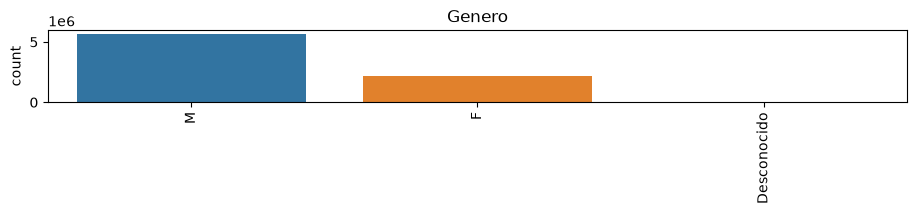

In [9]:
dataframe_getStatisticalDescription(df, False, 3, 2, len(cat_cols))